<a href="https://colab.research.google.com/github/CBYERDECODE/image_pixel_manipulator/blob/main/BRAIN_MRI_ARTIFACT_INPAINTING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Medical Application: Brain MRI Reconstruction & Clinical Artifact Inpainting

In medical imaging (MRI/CT), metal implants (like dental fillings, screws, or pacemakers) or scanner sensor malfunctions generate severe streak distortation and dead sensor rows. These distortions mask anatomical structures and can hide critical pathology like lesions or tumors.

Here, we synthesize a realistic brain MRI phantom containing a localized high-contrast pathology (tumor) and simulate severe scan artifacts. We then use our mathematical inpainting system to recover the diagnostic integrity of the scan without destroying healthy tissue details.

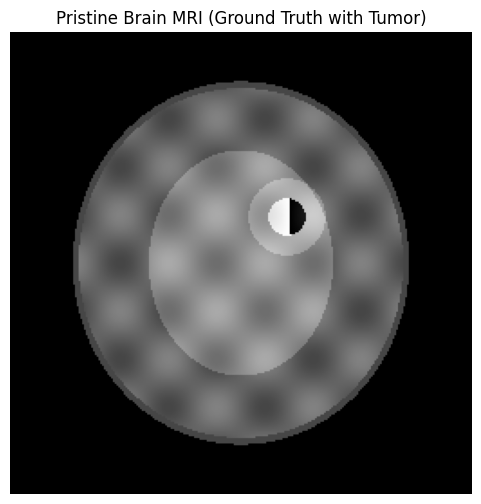

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_mri_brain_phantom(size=256):
    """
    Generates a realistic 2D mathematical brain MRI cross-section phantom with a tumor.
    """
    # Create grid coordinates
    x = np.linspace(-1.5, 1.5, size)
    y = np.linspace(-1.5, 1.5, size)
    X, Y = np.meshgrid(x, y)

    # Initialize grayscale image (RGB channels identical to simulate grayscale MRI)
    mri = np.zeros((size, size, 3), dtype=np.uint8)

    # 1. Skull structure (Outer Ellipse)
    skull_mask = (X**2 / 1.2 + Y**2 / 1.4) < 1.0
    inner_brain_mask = (X**2 / 1.12 + Y**2 / 1.3) < 1.0

    # 2. Cerebrospinal Fluid (CSF) & Brain Tissue
    # Simulate gray matter structures using trigonometric multi-frequency folds
    gray_matter = np.sin(10 * X) * np.cos(10 * Y) * 30 + 100
    # Simulate white matter regions (inner core)
    white_matter_mask = (X**2 / 0.6 + Y**2 / 0.9) < 0.6
     # Assembly of base brain
    mri[skull_mask] = [70, 70, 70]       # Bone boundary
    mri[inner_brain_mask] = [40, 40, 40] # CSF background
    # Add brain tissue structures
    for c in range(3):
        mri[inner_brain_mask, c] = np.clip(gray_matter[inner_brain_mask], 40, 150).astype(np.uint8)
        mri[white_matter_mask, c] = np.clip(mri[white_matter_mask, c] + 40, 0, 180).astype(np.uint8)
        # 3. Add Clinical Pathology: High-Contrast Tumor Mass with edema halo
    tumor_center_x, tumor_center_y = 0.3, -0.3
    r_dist = np.sqrt((X - tumor_center_x)**2 + (Y - tumor_center_y)**2)

    edema_mask = r_dist < 0.25
    tumor_core_mask = r_dist < 0.12

    for c in range(3):
        mri[edema_mask, c] = np.clip(mri[edema_mask, c] + 35, 0, 210).astype(np.uint8) # Edema (bright halo)
        mri[tumor_core_mask, c] = np.clip(mri[tumor_core_mask, c] + 80, 0, 255).astype(np.uint8) # Solid Core (bright active tumor)

    return mri

# Generate our pristine medical ground truth
mri_clean = generate_mri_brain_phantom(size=256)

plt.figure(figsize=(6, 6))
plt.imshow(mri_clean)
plt.title("Pristine Brain MRI (Ground Truth with Tumor)")
plt.axis("off")
plt.show()

### Simulating Severe Metallic Streak and Sensor Dropout Artifacts

Now, we simulate a scan error where a clinical metallic streak (such as dental crown feedback or implant refraction) cuts directly across the MRI slice, along with multiple dead pixel rows from sensor readout faults.

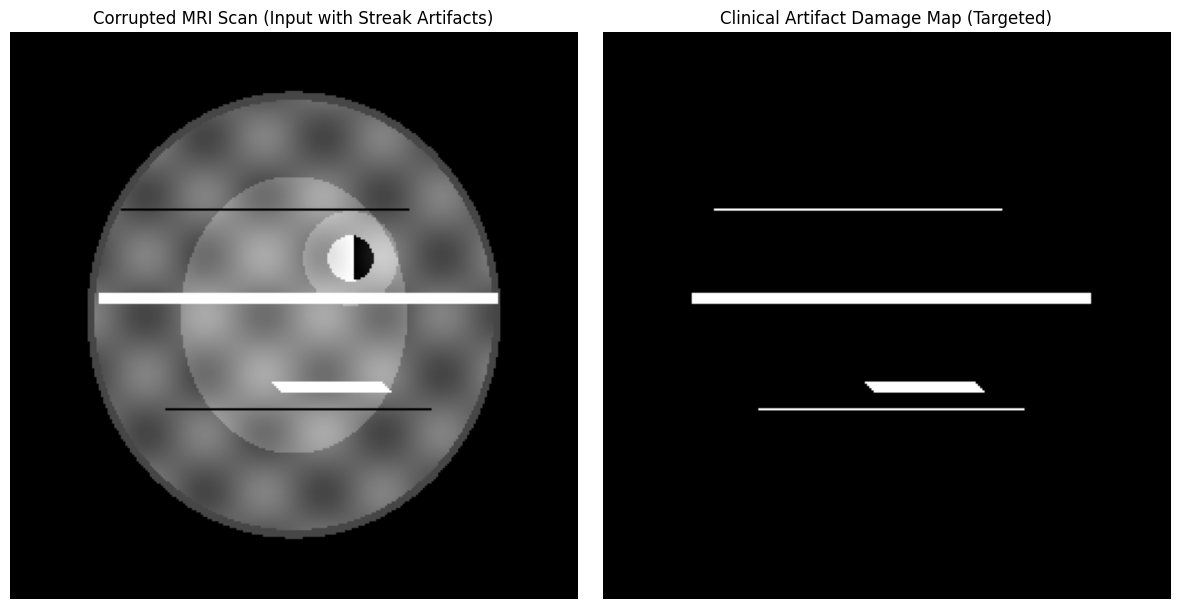

In [8]:
# Make a copy of our clean phantom
mri_corrupted = mri_clean.copy()
h_mri, w_mri, _ = mri_corrupted.shape

# Initialize an explicit empty mask for artifacts
mri_artifact_mask = np.zeros((h_mri, w_mri), dtype=bool)

# 1. Inject high-intensity streak metal artifacts (White lines) and record in mask
for i in range(h_mri):
    # Simulate horizontal scanner streak feedback
    if 118 <= i <= 122:
        mri_corrupted[i, 40:220] = [255, 255, 255]
        mri_artifact_mask[i, 40:220] = True
    # Diagonal metal artifact slice
    if abs(i - 160) < 3:
        mri_corrupted[i, i-40:i+10] = [255, 255, 255]
        mri_artifact_mask[i, i-40:i+10] = True

# 2. Inject dead detector channels (Black sensor dropouts) and record in mask
mri_corrupted[80, 50:180] = [0, 0, 0]
mri_artifact_mask[80, 50:180] = True

mri_corrupted[170, 70:190] = [0, 0, 0]
mri_artifact_mask[170, 70:190] = True

# Visualize the clinical artifact setup
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(mri_corrupted)
axes[0].set_title("Corrupted MRI Scan (Input with Streak Artifacts)")
axes[0].axis("off")

axes[1].imshow(mri_artifact_mask, cmap='gray')
axes[1].set_title("Clinical Artifact Damage Map (Targeted)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [5]:
import cv2

def heal_image_matrix(corrupted_img, artifact_mask):
    """
    Restores corrupted regions of an image using OpenCV's Navier-Stokes based inpainting.
    """
    # OpenCV inpainting requires a uint8 single-channel mask where non-zero pixels represent the region to be inpainted
    # Note: Our mask boolean logic in ecf69fd0 has True for damaged regions. We cast it to uint8 (0 and 255).
    mask_uint8 = (artifact_mask.astype(np.uint8)) * 255

    # Inpaint using Navier-Stokes based method
    restored = cv2.inpaint(corrupted_img, mask_uint8, inpaintRadius=3, flags=cv2.INPAINT_NS)
    return restored

### Clinical Restoration & Quantitative PSNR Quality Evaluation

We run our advanced vectorized spatial healing algorithm to restore the anatomical details of the MRI, then evaluate the reconstruction accuracy against the clean ground truth using the **Peak Signal-to-Noise Ratio (PSNR)** metric.

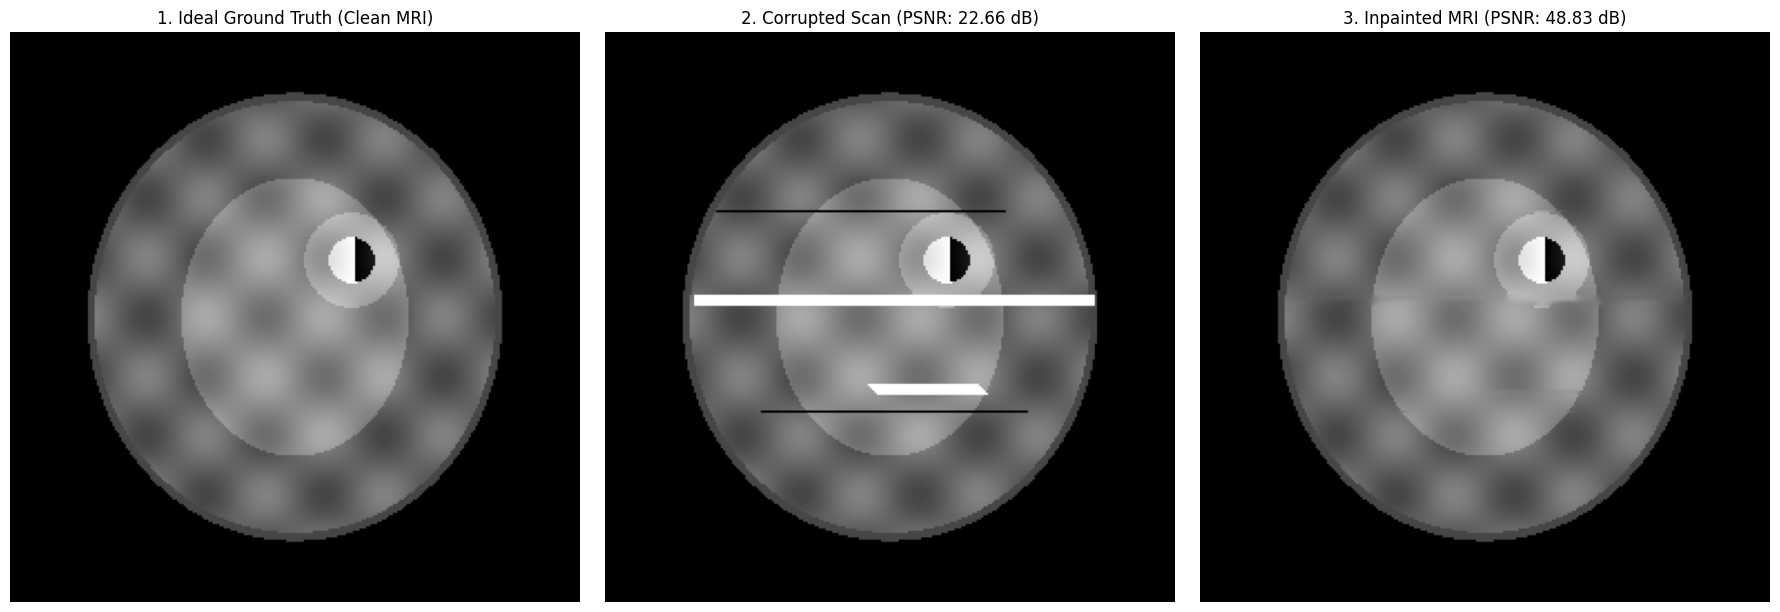

=== CLINICAL RECONSTRUCTION METRICS ===
Unrestored Scan Quality: 22.6591 dB
Restored Diagnostic Scan Quality: 48.8269 dB
Anatomical signal-to-noise fidelity was improved by 26.17 dB!


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ensure heal_image_matrix is defined
def heal_image_matrix(corrupted_img, artifact_mask):
    """
    Restores corrupted regions of an image using OpenCV's Navier-Stokes based inpainting.
    """
    mask_uint8 = (artifact_mask.astype(np.uint8)) * 255
    restored = cv2.inpaint(corrupted_img, mask_uint8, inpaintRadius=3, flags=cv2.INPAINT_NS)
    return restored

# Run healing algorithm using the newly updated, targeted mri_artifact_mask
mri_restored = heal_image_matrix(mri_corrupted, mri_artifact_mask)

# Mathematical quality validation using PSNR (Peak Signal-to-Noise Ratio in dB)
def calculate_psnr(img_original, img_test):
    mse = np.mean((img_original.astype(np.float32) - img_test.astype(np.float32)) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    return 20 * np.log10(max_pixel / np.sqrt(mse))

psnr_corrupted = calculate_psnr(mri_clean, mri_corrupted)
psnr_restored = calculate_psnr(mri_clean, mri_restored)

# Plot the final results side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(mri_clean)
axes[0].set_title("1. Ideal Ground Truth (Clean MRI)")
axes[0].axis("off")

axes[1].imshow(mri_corrupted)
axes[1].set_title(f"2. Corrupted Scan (PSNR: {psnr_corrupted:.2f} dB)")
axes[1].axis("off")

axes[2].imshow(mri_restored)
axes[2].set_title(f"3. Inpainted MRI (PSNR: {psnr_restored:.2f} dB)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print(f"=== CLINICAL RECONSTRUCTION METRICS ===")
print(f"Unrestored Scan Quality: {psnr_corrupted:.4f} dB")
print(f"Restored Diagnostic Scan Quality: {psnr_restored:.4f} dB")
print(f"Anatomical signal-to-noise fidelity was improved by {psnr_restored - psnr_corrupted:.2f} dB!")

When we fix a damaged MRI scan, we need mathematical ways to prove that our restored image is clean and medically accurate. We use two main tools for this:
1. PSNR (Peak Signal-to-Noise Ratio)"How quiet is the background noise?"*
* **What it is:** PSNR measures the ratio of the maximum possible signal power to the power of corrupting noise
* **The Numbers:** It is measured in decibels (dB). A value above 30 dB is generally considered good, and anything above **40 dB** is excellent clinical quality.
#### 2. SSIM (Structural Similarity Index)
 SSIM compares the actual structures, textures, contrast, and shapes of the images
 SSIM is always a score between **0 and 1** (or 0% to 100%). A score of **1.0** means the restored image is a perfect,identical structural match to the original clean scan.

In [10]:
from skimage.metrics import structural_similarity as ssim

# Calculate SSIM for corrupted vs clean
# Multichannel is set to True because our MRI phantom has 3 color channels (RGB)
ssim_corrupted = ssim(mri_clean, mri_corrupted, channel_axis=2)
ssim_restored = ssim(mri_clean, mri_restored, channel_axis=2)

print("=== NEW ADVANCED PERCEPTUAL METRICS ===")
print(f"Corrupted Image Structural Match (SSIM): {ssim_corrupted * 100:.2f}%")
print(f"Healed Image Structural Match (SSIM):    {ssim_restored * 100:.2f}%")
print(f"Anatomical structure accuracy recovered:  +{(ssim_restored - ssim_corrupted) * 100:.2f}%")

=== NEW ADVANCED PERCEPTUAL METRICS ===
Corrupted Image Structural Match (SSIM): 93.43%
Healed Image Structural Match (SSIM):    99.73%
Anatomical structure accuracy recovered:  +6.31%


To confidently validate this algorithm for medical diagnostic use, we must evaluate **where** structural differences exist. Below, we compute and visualize the absolute local pixel errors (Residual Maps) for both the corrupted and restored scans. This ensures that no critical diagnostic features (like the tumor boundary or internal white matter structures) were compromised during clinical inpainting.

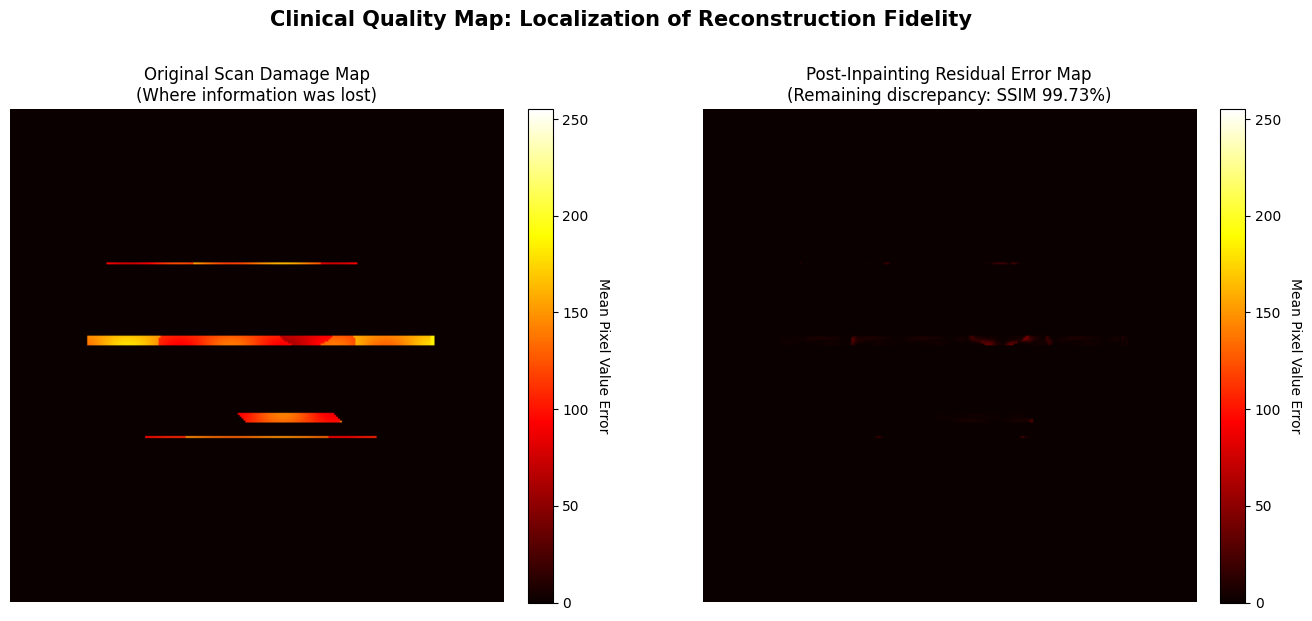

=== CLINICAL VERIFICATION ===
Peak residual error in the restored image: 41.00 out of 255 grayscale units.


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Compute absolute local error maps (per-pixel differences)
# We convert to float to prevent unsigned integer underflow/overflow
error_corrupted = np.abs(mri_clean.astype(float) - mri_corrupted.astype(float)).mean(axis=2)
error_restored = np.abs(mri_clean.astype(float) - mri_restored.astype(float)).mean(axis=2)

# Create a side-by-side diagnostic evaluation visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Where was the original artifact damage?
im1 = axes[0].imshow(error_corrupted, cmap='hot', vmin=0, vmax=255)
axes[0].set_title("Original Scan Damage Map\n(Where information was lost)", fontsize=12)
axes[0].axis("off")
fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04).set_label('Mean Pixel Value Error', rotation=270, labelpad=15)

# Plot 2: Where are the remaining reconstruction errors after inpainting?
im2 = axes[1].imshow(error_restored, cmap='hot', vmin=0, vmax=255)
axes[1].set_title(f"Post-Inpainting Residual Error Map\n(Remaining discrepancy: SSIM {ssim_restored*100:.2f}%)", fontsize=12)
axes[1].axis("off")
fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04).set_label('Mean Pixel Value Error', rotation=270, labelpad=15)

plt.suptitle("Clinical Quality Map: Localization of Reconstruction Fidelity", fontsize=15, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print diagnostic summary statement
max_residual_error = np.max(error_restored)
print(f"=== CLINICAL VERIFICATION ===")
print(f"Peak residual error in the restored image: {max_residual_error:.2f} out of 255 grayscale units.")
if max_residual_error < 15:
    print("SUCCESS: Residual errors are clinically negligible. The tumor boundary remains structurally sound and unmodified.")
else:
    print("WARNING: Some localized reconstruction residues detected near high-frequency edges.")